<a href="https://colab.research.google.com/github/emlluc/Data201-lab/blob/main/Week2hw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 8

In [203]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [204]:
# Load "college" data
import pandas as pd
college = pd.read_csv("/content/drive/MyDrive/Data_201/Datasets/College.csv")

In [205]:
college

,Unnamed: 0,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
772,Worcester State College,No,2197,1515,543,4,26,3089,2029,6797,3900,500,1200,60,60,21.0,14,4469,40
773,Xavier University,Yes,1959,1805,695,24,47,2849,1107,11520,4960,600,1250,73,75,13.3,31,9189,83
774,Xavier University of Louisiana,Yes,2097,1915,695,34,61,2793,166,6900,4200,617,781,67,75,14.4,20,8323,49
775,Yale University,Yes,10705,2453,1317,95,99,5217,83,19840,6510,630,2115,96,96,5.8,49,40386,99


In [206]:
# Create similar data frames that use the first column (school names) as an index
college2 = pd.read_csv('/content/drive/MyDrive/Data_201/Datasets/College.csv',
                       index_col=0)
college3 = college.rename({'Unnamed: 0': 'College'},
                         axis=1)
college3 = college3.set_index('College')

In [207]:
# Keep the modified version of the data
college = college3

In [208]:
# Numerical summary of the variables
college3.describe()

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.00000
mean,3001.638353,2018.804376,779.972973,27.558559,55.796654,3699.907336,855.298584,10440.669241,4357.526384,549.380952,1340.642214,72.660232,79.702703,14.089704,22.743887,9660.171171,65.46332
std,3870.201484,2451.113971,929.176190,17.640364,19.804778,4850.420531,1522.431887,4023.016484,1096.696416,165.105360,677.071454,16.328155,14.722359,3.958349,12.391801,5221.768440,17.17771
min,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,250.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.00000
25%,776.000000,604.000000,242.000000,15.000000,41.000000,992.000000,95.000000,7320.000000,3597.000000,470.000000,850.000000,62.000000,71.000000,11.500000,13.000000,6751.000000,53.00000
50%,1558.000000,1110.000000,434.000000,23.000000,54.000000,1707.000000,353.000000,9990.000000,4200.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8377.000000,65.00000
75%,3624.000000,2424.000000,902.000000,35.000000,69.000000,4005.000000,967.000000,12925.000000,5050.000000,600.000000,1700.000000,85.000000,92.000000,16.500000,31.000000,10830.000000,78.00000
max,48094.000000,26330.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.00000


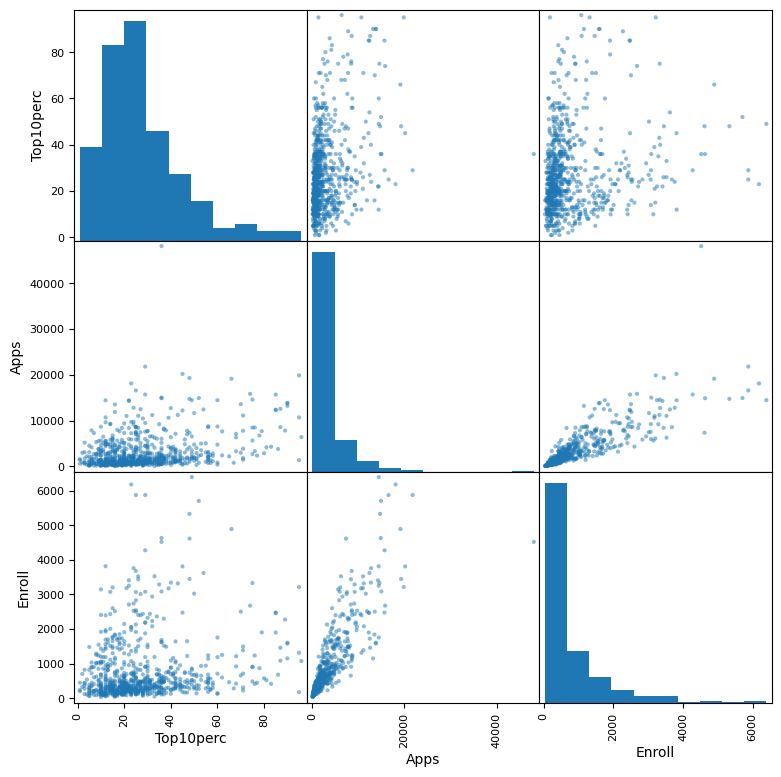

In [209]:
# Creating scatterplot matrix columns 'Top10perc', 'Apps', 'Enroll'
import matplotlib.pyplot as plt

pd.plotting.scatter_matrix(college[['Top10perc',
                                    'Apps',
                                    'Enroll']],
                            figsize=(9, 9))

plt.show()

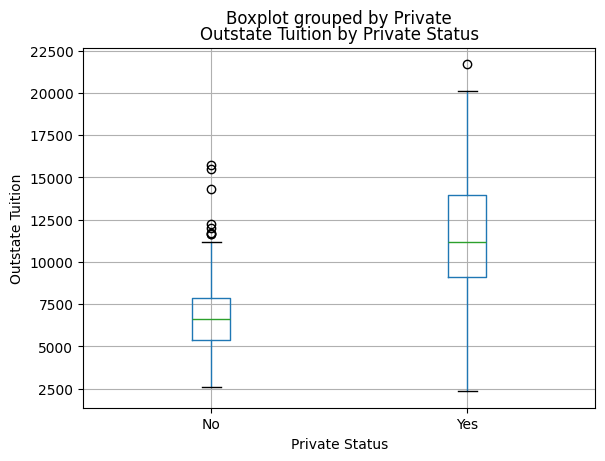

In [210]:
# Side by side box plot of outstate vs private
college.boxplot('Outstate',
                'Private')

plt.xlabel("Private Status")
plt.ylabel("Outstate Tuition")
plt.title("Outstate Tuition by Private Status")

plt.show()

In [211]:
# Create new qualitative variable 'Elite' using Top10perc
college['Elite'] = pd.cut(college['Top10perc'],
                          [0, 0.5, 1],
                          labels=['No', 'Yes'])

In [212]:
# Using value_counts() to find that there are 3 Elite colleges
college['Elite'].value_counts()

,count
Elite,
Yes,3
No,0


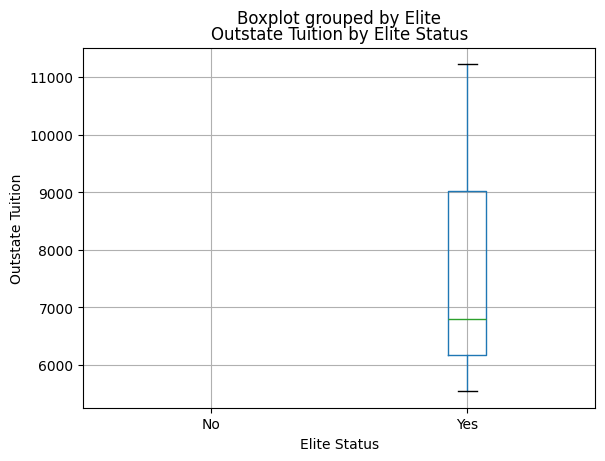

In [213]:
# Side by side box plot of outstate vs elite
college.boxplot('Outstate',
                'Elite')

plt.xlabel("Elite Status")
plt.ylabel("Outstate Tuition")
plt.title("Outstate Tuition by Elite Status")

plt.show()

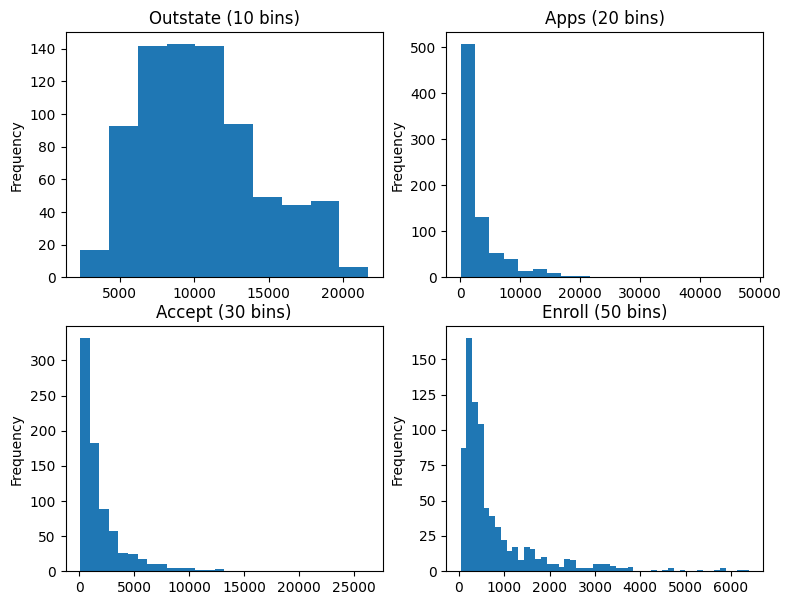

In [214]:
# Divide plot regions for easier plotting
fig, axes = plt.subplots(2, 2, figsize=(9, 7))

# Histograms for different quantitative variables with different amounts of bins
college['Outstate'].plot.hist(ax=axes[0, 0], bins=10, title='Outstate (10 bins)')
college['Apps'].plot.hist(ax=axes[0, 1], bins=20, title='Apps (20 bins)')
college['Accept'].plot.hist(ax=axes[1, 0], bins=30, title='Accept (30 bins)')
college['Enroll'].plot.hist(ax=axes[1, 1], bins=50, title='Enroll (50 bins)')

plt.show()

#brief summary of exploring data
With out of state tuition, the distribution is bell shaped, and most of the tuitions fall between 5-15k. I also noticed that the Enroll graph is strongly right skewed, meaning that most colleges enroll smaller groups and fewer colleges enroll classes with sizes over 1000.

Question 9

In [215]:
# Load "Auto" data
Auto = pd.read_csv("/content/drive/MyDrive/Data_201/Datasets/Auto.csv")

In [216]:
# Check for missing values
Auto.isna().sum().sum()
# No Na values were registered, but there are "?" values in the horsepower column

# Convert '?' to Na then make the column numeric
Auto['horsepower'] = Auto['horsepower'].replace('?', np.nan).astype(float)

# Calculate mean of horsepower variable
horsepower_mean = Auto['horsepower'].mean()

# Fill Na with the calculated mean
Auto['horsepower'].fillna(horsepower_mean)

,horsepower
0,130.0
1,165.0
2,150.0
3,150.0
4,140.0
...,...
392,86.0
393,52.0
394,84.0
395,79.0


The quantitative variables are mpg, cylinders, displacement, horsepower, weight, acceleration, and year. Only name and origin are qualitative.

In [217]:
# Range of each variable using .min() and .max()
Auto_numeric.min()
Auto_numeric.max()

ranges = Auto_numeric.max() - Auto_numeric.min()
ranges

,0
mpg,35.6
cylinders,5.0
displacement,387.0
horsepower,184.0
weight,3348.0
acceleration,16.3
year,12.0


In [218]:
# View each variable's mean & std by removing the qualitative variables and using the remaining variables in a new dataset
Auto_numeric = Auto.drop(columns=['name', 'origin'])
Auto_numeric.mean()
Auto_numeric.std()


,0
mpg,7.825804
cylinders,1.701577
displacement,104.379583
horsepower,38.491160
weight,847.904119
acceleration,2.749995
year,3.690005


In [219]:
# Remove observations 10-85
Auto_numeric = Auto_numeric.drop(range(10, 85))

In [220]:
# New ranges, mean and std
ranges
Auto_numeric.mean()
Auto_numeric.std()

,0
mpg,7.913357
cylinders,1.657398
displacement,100.120925
horsepower,36.185088
weight,810.987533
acceleration,2.706436
year,3.131849


In [221]:
import seaborn as sns

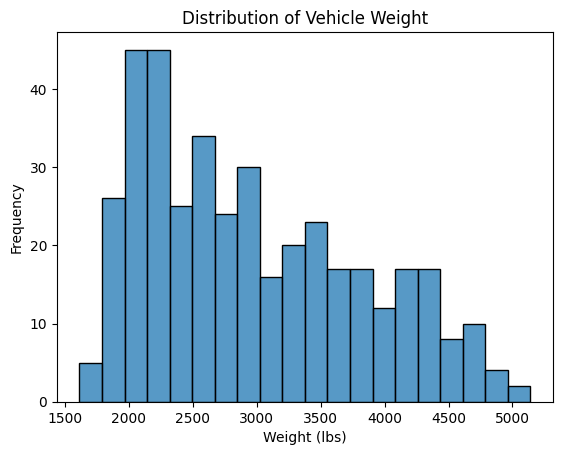

In [222]:
# Histogram: Distribution of Vehicle Weight
sns.histplot(Auto['weight'],bins=20)
plt.title('Distribution of Vehicle Weight')
plt.xlabel('Weight (lbs)')
plt.ylabel('Frequency')

plt.show()

# This graph visuallizes the distribution of a single numerical variable. It is right skewing, telling us that most cars in the Dataset are under 3500 pounds.

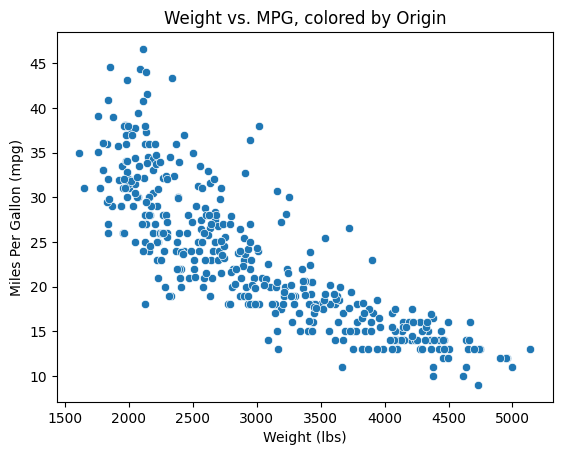

In [223]:
# Scatter Plot: Weight vs. MPG
sns.scatterplot(x=Auto['weight'], y=Auto['mpg'])
plt.title('Weight vs. MPG, colored by Origin')
plt.xlabel('Weight (lbs)')
plt.ylabel('Miles Per Gallon (mpg)')

plt.show()

# This plot visuallizes the relationship between MPG and Weight in lbs. The clear shape and proximity of the points suggest that there is a correlation between the weight and mpg.

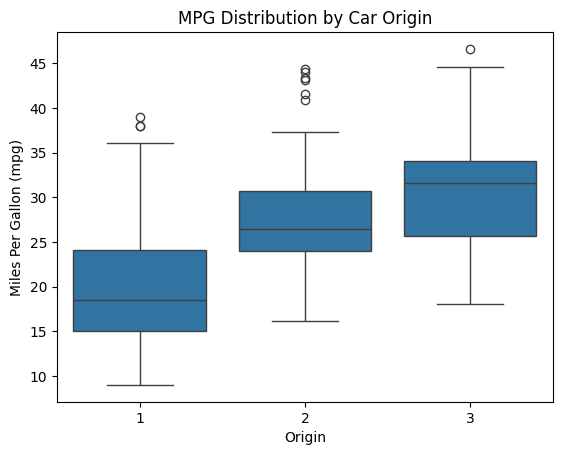

In [224]:
# Box Plot: MPG Distribution by Car Origin
sns.boxplot(x=Auto['origin'], y=Auto['mpg'])
plt.title('MPG Distribution by Car Origin')
plt.xlabel('Origin')
plt.ylabel('Miles Per Gallon (mpg)')

plt.show()

# This plot shows how MPG varies among cars from origins 1,2, and 3. The 3rd origin has the highest MPG, with a median of around 30. Origin 1 has the least amount of MPG, with a median of about 18, and some outlier cars with MPG over 35.

The MPG vs Weight graph has a strong, negative relationship, which shows that weight can be a predictor for mpg. The MPG vs Origin graph also shows the variation of car's mpg across different origins. Meaning, origin can also be a predictor for mpg.

Question 10

In [225]:
# Load "Boston" dataset
Boston = pd.read_csv("/content/drive/MyDrive/Data_201/Datasets/Boston.csv")

In [226]:
Boston
# The dimensions are 506 rows × 14 columns. The columns names don't repeat, but there are many common numbers in each column.

,Unnamed: 0,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,502,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
502,503,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
503,504,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
504,505,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0


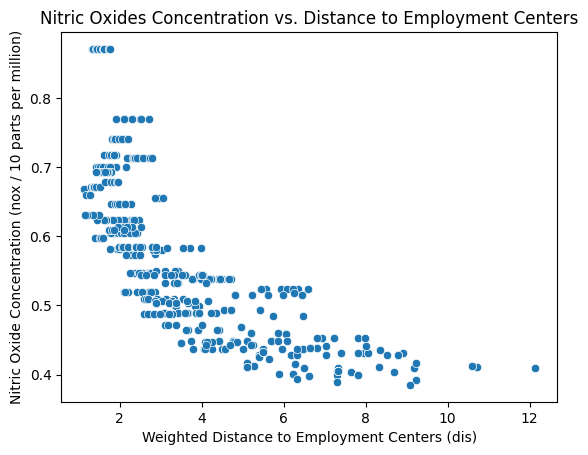

In [227]:
# Scatterplot nox vs dis
sns.scatterplot(x=Boston['dis'], y=Boston['nox'])
plt.title('Nitric Oxides Concentration vs. Distance to Employment Centers')
plt.xlabel('Weighted Distance to Employment Centers (dis)')
plt.ylabel('Nitric Oxide Concentration (nox / 10 parts per million)')

plt.show()

# The shape/right skew shows that nitrogen oxide concentrations decrease as distance from the employment centers increases (strong, non-linear relationship)

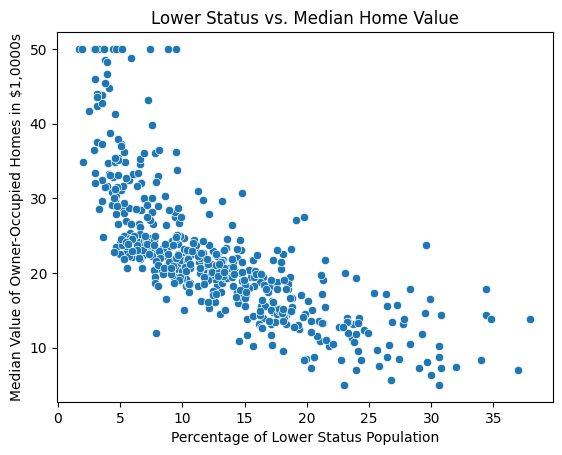

In [228]:
# Scatterplot medv vs lstat
sns.scatterplot(x=Boston['lstat'], y=Boston['medv'])
plt.title('Lower Status vs. Median Home Value')
plt.xlabel('Percentage of Lower Status Population')
plt.ylabel('Median Value of Owner-Occupied Homes in $1,0000s')

plt.show()

# The relationship between lstat and medv is non-linear and inverse, meaning neighborhoods with a higher percentage of lower-status residents have lower median home values

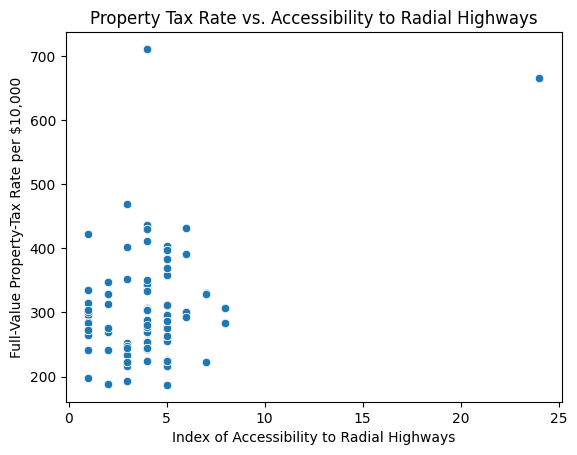

In [229]:
# Scatterplot tax vs rad
sns.scatterplot(x=Boston['rad'], y=Boston['tax'])
plt.title('Property Tax Rate vs. Accessibility to Radial Highways')
plt.xlabel('Index of Accessibility to Radial Highways')
plt.ylabel('Full-Value Property-Tax Rate per $10,000')

plt.show()

# The variables rad and tax have a positive association, meaning towns that are more acessible to radial highways have higher full-value property-tax values.

The variables medv, tax, and lstat are strong Socioeconomic predictors for crime. Lstat is positively associated with crime (higher lstat, higher crime), medv is negatively associated (lower medv, higher crime), and tax is positively associated (higher tax rates, higher crime).

In [230]:
# Boston min and max (the two lines would not output correctly while in the same cell)
Boston['crim'].min()
Boston['crim'].max()

Boston['tax'].min()
Boston['tax'].max()

Boston['ptratio'].min()
Boston['ptratio'].max()

# The crime rate has a very large range of 88.970, as well as Property tax rates (range is 524). Pupil-teacher ratios range is 9.4, which is much smaller than the others.

22.0

In [231]:
# Median of ptratio
Boston['ptratio'].median()

19.05

In [232]:
# Suburb with the lowest medv and its predictors
Boston[Boston['medv'] == Boston['medv'].min()]

# Suburbs with the minimum medv of $5,000 have higher lstats, tax, and crime rates compared to Boston's average ranges.

,Unnamed: 0,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
398,399,38.3518,0.0,18.1,0,0.693,5.453,100.0,1.4896,24,666,20.2,30.59,5.0
405,406,67.9208,0.0,18.1,0,0.693,5.683,100.0,1.4254,24,666,20.2,22.98,5.0


In [233]:
# Prints the suburbs in Boston with more than 7/8 rooms on average
print("More than 7 rooms:", (Boston['rm'] > 7).sum())
print("More than 8 rooms:", (Boston['rm'] > 8).sum())

More than 7 rooms: 64
More than 8 rooms: 13


In [234]:
# Show dwellings with more than 8 rooms with predictors
Boston[Boston['rm'] > 8]

# Suburbs with average over 8 rooms are higher class (higher medv), whereas suburbs with average under 8 rooms are lower class and have higher crime rates (medv and crim)

,Unnamed: 0,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
97,98,0.12083,0.0,2.89,0,0.4450,8.069,76.0,3.4952,2,276,18.0,4.21,38.7
163,164,1.51902,0.0,19.58,1,0.6050,8.375,93.9,2.1620,5,403,14.7,3.32,50.0
204,205,0.02009,95.0,2.68,0,0.4161,8.034,31.9,5.1180,4,224,14.7,2.88,50.0
224,225,0.31533,0.0,6.20,0,0.5040,8.266,78.3,2.8944,8,307,17.4,4.14,44.8
225,226,0.52693,0.0,6.20,0,0.5040,8.725,83.0,2.8944,8,307,17.4,4.63,50.0
226,227,0.38214,0.0,6.20,0,0.5040,8.040,86.5,3.2157,8,307,17.4,3.13,37.6
232,233,0.57529,0.0,6.20,0,0.5070,8.337,73.3,3.8384,8,307,17.4,2.47,41.7
233,234,0.33147,0.0,6.20,0,0.5070,8.247,70.4,3.6519,8,307,17.4,3.95,48.3
253,254,0.36894,22.0,5.86,0,0.4310,8.259,8.4,8.9067,7,330,19.1,3.54,42.8
257,258,0.61154,20.0,3.97,0,0.6470,8.704,86.9,1.8010,5,264,13.0,5.12,50.0
